# 01 - Ingesta MIBGAS -> raw

Este notebook descarga los ficheros CSV anuales oficiales de MIBGAS y conserva la respuesta original en `data/raw/mibgas/`. Se selecciona posteriormente el producto diario D+1 (`GDAES_D+1`) durante la calidad.

In [13]:
import sys
from pathlib import Path

import pandas as pd

PROJECT_ROOT = Path.cwd()
for candidate in (PROJECT_ROOT, *PROJECT_ROOT.parents):
    if (candidate / 'requirements.txt').is_file() and (candidate / 'notebooks').is_dir():
        PROJECT_ROOT = candidate
        break
else:
    raise FileNotFoundError('No se encontro la raiz del proyecto.')

sys.path.insert(0, str(PROJECT_ROOT))
from src.project import find_project_root

PROJECT_ROOT = find_project_root(PROJECT_ROOT)
from src.config.mibgas import load_mibgas_config
from src.ingesta.mibgas import MibgasIngestionConfig, ingest_year

MIBGAS_CONFIG_PATH = PROJECT_ROOT / 'config' / 'mibgas.yaml'
MODEL_CONFIG_PATH = PROJECT_ROOT / 'config' / 'modelo.yaml'
CONFIG = load_mibgas_config(MIBGAS_CONFIG_PATH, MODEL_CONFIG_PATH)
MIBGAS = CONFIG['mibgas']
MODEL = MIBGAS['model']
INGESTION = MIBGAS['ingestion']
RAW_DIR = PROJECT_ROOT / 'data' / 'raw' / 'mibgas'
START = pd.Timestamp(MODEL['history_start']).date()
END = pd.Timestamp(MODEL['history_end']).date()
YEARS = list(range(START.year, END.year + 1))
ingestion_settings = {**INGESTION, 'timeout': INGESTION['timeout_seconds']}
del ingestion_settings['timeout_seconds']
INGESTION_CONFIG = MibgasIngestionConfig(raw_dir=RAW_DIR, **ingestion_settings)
print(f'Ventana historica: {START} a {END}')
print(f'Ficheros anuales previstos: {YEARS}')
print(f'Destino raw: {RAW_DIR}')

Ventana historica: 2024-10-01 a 2026-09-30
Ficheros anuales previstos: [2024, 2025, 2026]
Destino raw: c:\Users\zhen.xiang\OneDrive - Accenture\Documents\SAT\Energy\odb-challenge-energy-optimizer\data\raw\mibgas


## 1. Plan de descarga

MIBGAS publica un CSV anual por año. La tabla permite revisar el plan antes de descargar.

In [14]:
plan = pd.DataFrame({'year': YEARS})
plan['file'] = plan['year'].map(lambda x: f'MIBGAS_Data_{x}.csv')
plan['url'] = plan['year'].map(lambda x: INGESTION_CONFIG.base_url.rstrip('/') + INGESTION_CONFIG.file_path_template.format(language=INGESTION_CONFIG.language, year=x))
plan

,year,file,url
0,2024,MIBGAS_Data_2024.csv,https://www.mibgas.es/es/file-access/MIBGAS_Da...
1,2025,MIBGAS_Data_2025.csv,https://www.mibgas.es/es/file-access/MIBGAS_Da...
2,2026,MIBGAS_Data_2026.csv,https://www.mibgas.es/es/file-access/MIBGAS_Da...


## 2. Descarga de los ficheros raw

La celda realiza la descarga real. Los ficheros existentes se omiten cuando `force` está desactivado.

In [15]:
results = [ingest_year(year, INGESTION_CONFIG) for year in YEARS]
results_frame = pd.DataFrame(results, columns=['status', 'path', 'records'])
results_frame

,status,path,records
0,skipped,c:\Users\zhen.xiang\OneDrive - Accenture\Docum...,1131
1,skipped,c:\Users\zhen.xiang\OneDrive - Accenture\Docum...,1129
2,skipped,c:\Users\zhen.xiang\OneDrive - Accenture\Docum...,1131


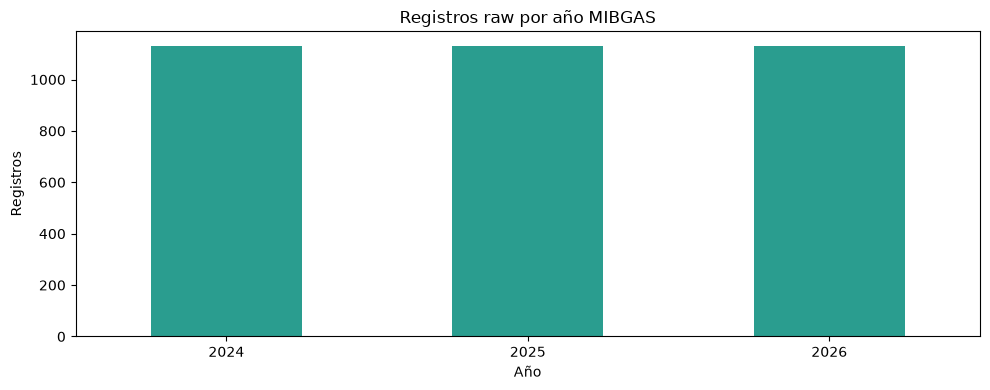

In [16]:
results_frame['year'] = YEARS
results_frame.plot.bar(x='year', y='records', legend=False, figsize=(10, 4), color='#2a9d8f', title='Registros raw por año MIBGAS')
plt.ylabel('Registros')
plt.xlabel('Año')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()